# 02 · Harder synthetic data

Answers Q1–Q6 on **hard** data (5 seeds per cell; ladder in notebook 00). Each section:
question and outcomes → run → table/plot → the outcome picked by the pre-registered rule.
All raw results are saved to `notebooks_sharedness/results/hard_*.csv`.

In [1]:
import os, sys, warnings
os.environ["TQDM_DISABLE"] = "1"
warnings.filterwarnings("ignore")
ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks_sharedness" else os.getcwd()
sys.path.insert(0, ROOT)
os.chdir(ROOT)

import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import Markdown, display
from sharedness import experiments as ex, metrics as mt
from sharedness.data import make_view_data, H_EASY, pattern_for

pd.set_option("display.precision", 3)
sns.set_theme(style="whitegrid", context="notebook")
RESULTS = os.path.join(ROOT, "notebooks_sharedness", "results")
os.makedirs(RESULTS, exist_ok=True)

def outcome(code_text, title="Observed outcome"):
    code, text = code_text
    display(Markdown(f"> **{title}: {code}** — {text}"))
    return code

LEVEL = "hard"
SEEDS = range(5)

## Q1 — Can CohortFACTM learn how often cohorts differ?

CohortFACTM gives every (cohort, factor) pair a switch $\gamma_{ck}$: *does cohort $c$ have its
own centre on factor $k$?* Today the switch rate $\pi$ is a number we pick (0.5). If we let the model
**learn** $\pi$, does it find the true rate?

| Outcome | Name | What we would see | What it would mean |
|---|---|---|---|
| **O1** | Learnable | max $|\mathbb E[\pi]-\pi^\ast| < 0.15$ and slope $>0.5$ | the data carry the rate; keep $\pi$ learnable |
| **O2** | Drifts to 1 | $\mathbb E[\pi] > 0.8$ at every $\pi^\ast$ | switches are never pushed off; the factorisation, not the formula, is at fault |
| **O3** | Prior-dominated | $\mathbb E[\pi]$ moves $<0.2$ across $\pi^\ast$ | too few switches ($CK$) to learn from; fix $\pi$ |
| **O4** | Partial | anything else | moves with the truth but biased; report the bias |

*Full mathematical statement: notebook 00.*

In [2]:
q1 = ex.run_q1(LEVEL, seeds=SEEDS)
q1.to_csv(os.path.join(RESULTS, f"{LEVEL}_q1.csv"), index=False)
summary = (q1.groupby(["arm", "rate"])
             [["true_rate", "E_pi", "sd_pi", "mean_gamma_null", "mean_gamma_alt", "auc_gamma", "monotone"]]
             .mean())
summary

true_rate   E_pi  sd_pi  mean_gamma_null  \
arm                    rate                                             
fixed pi=0.5 (current) 0.1       0.078  0.500  0.000            0.094   
                       0.3       0.278  0.500  0.000            0.157   
                       0.6       0.578  0.500  0.000            0.213   
learned pi (current q) 0.1       0.078  0.079  0.036            0.029   
                       0.3       0.278  0.133  0.047            0.054   
                       0.6       0.578  0.334  0.066            0.199   
learned pi (paired q)  0.1       0.078  0.162  0.049            0.124   
                       0.3       0.278  0.449  0.069            0.396   
                       0.6       0.578  0.684  0.063            0.591   

                             mean_gamma_alt  auc_gamma  monotone  
arm                    rate                                       
fixed pi=0.5 (current) 0.1            0.960      0.983       1.0  
                       0.3            0.665      0.849       1.0  
                       0.6            0.625      0.805       1.0  
learned pi (current q) 0.1            0.680      0.855       1.0  
                       0.3            0.435      0.756       1.0  
                       0.6            0.597      0.792       1.0  
learned pi (paired q)  0.1            0.962      0.969       1.0  
                       0.3            0.910      0.912       1.0  
                       0.6            0.917      0.901       1.0

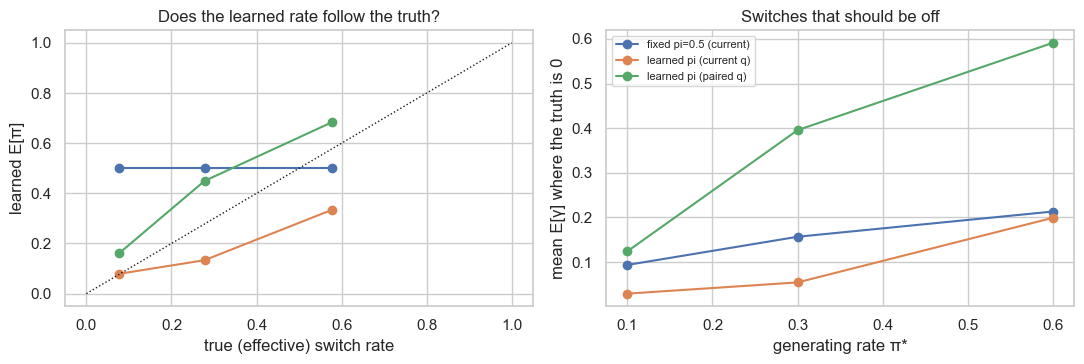

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for arm, d in q1.groupby("arm"):
    g = d.groupby("rate")[["true_rate", "E_pi"]].mean()
    axes[0].plot(g["true_rate"], g["E_pi"], "o-", label=arm)
    g2 = d.groupby("rate")["mean_gamma_null"].mean()
    axes[1].plot(g.index, g2, "o-", label=arm)
axes[0].plot([0, 1], [0, 1], "k:", lw=1); axes[0].set_xlabel("true (effective) switch rate")
axes[0].set_ylabel("learned E[π]"); axes[0].set_title("Does the learned rate follow the truth?")
axes[1].set_xlabel("generating rate π*"); axes[1].set_ylabel("mean E[γ] where the truth is 0")
axes[1].set_title("Switches that should be off"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

In [4]:
for arm in ["learned pi (current q)", "learned pi (paired q)"]:
    outcome(ex.decide_q1(q1, arm), title=f"Observed outcome [{arm}]")

> **Observed outcome [learned pi (current q)]: O4** — PARTIAL: E[pi] moves with the truth (slope 0.52) but is biased (max error 0.24).

> **Observed outcome [learned pi (paired q)]: O4** — PARTIAL: E[pi] moves with the truth (slope 1.02) but is biased (max error 0.17).

## Q2 — Can a plain fit, with no new parts, already show which factors are shared?

Fit the model we already have. For each factor, ask each view *how much of you does this factor
explain?* If the answer is ~0 in some views and large in others, the fit has told us the pattern
for free.

| Outcome | Name | What we would see | What it would mean |
|---|---|---|---|
| **O1** | Yes, any fit | AUC $\ge 0.95$ with and without ARD | sharedness is a read-out; no new model needed to *see* it |
| **O2** | Yes, with ARD | AUC $\ge 0.95$ only with ARD | ARD is what makes it readable |
| **O3** | Partly | best AUC in $[0.75, 0.95)$ | some cells wrong; inspect leaks |
| **O4** | No | best AUC $<0.75$ | the fit does not expose the pattern |

*Full mathematical statement: notebook 00.*

In [5]:
q2 = ex.run_q2(LEVEL, seeds=SEEDS)
q2[["arm", "seed", "auc_r", "auc_ard", "leak_r", "miss_r", "exact_r", "min_corr", "surplus_share",
    "monotone", "n_iter"]].to_csv(os.path.join(RESULTS, f"{LEVEL}_q2.csv"), index=False)
q2.groupby("arm")[["auc_r", "auc_ard", "leak_r", "miss_r", "exact_r", "min_corr", "surplus_share"]].mean()

,auc_r,auc_ard,leak_r,miss_r,exact_r,min_corr,surplus_share
arm,,,,,,,
ARD,0.968,0.950,0.2,1.4,4.8,0.460,0.000
ARD_truthstart,0.971,0.965,0.0,0.8,5.2,0.448,0.000
NONE,0.874,NaN,3.6,2.0,2.6,0.310,0.014


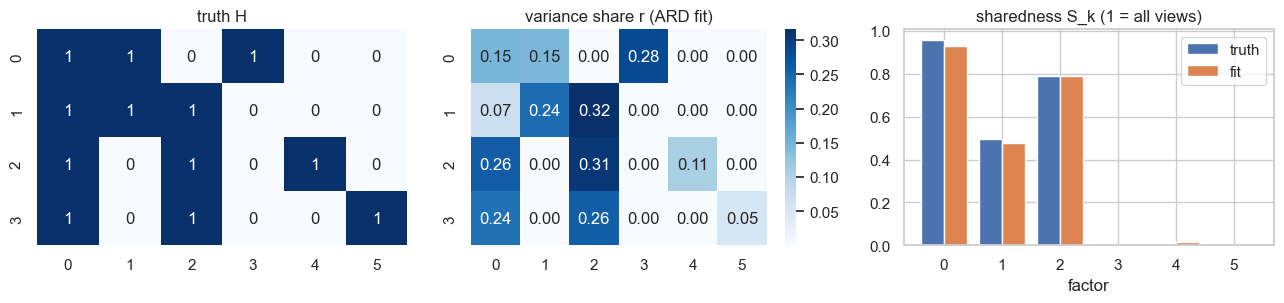

In [6]:
# One fit, drawn: the variance-share matrix next to the truth.
row = q2[(q2.arm == "ARD") & (q2.seed == 0)].iloc[0]
ds0, _ = ex.level_data(LEVEL, 0)
r = row["r"][:, row["match_idx"]]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
sns.heatmap(ds0.H, ax=axes[0], cmap="Blues", cbar=False, annot=True); axes[0].set_title("truth H")
sns.heatmap(r, ax=axes[1], cmap="Blues", annot=True, fmt=".2f"); axes[1].set_title("variance share r (ARD fit)")
S_true = mt.sharedness_entropy(mt.variance_share(ds0.Z, ds0.Ws, ds0.Ys))
S_fit = row["S_fit"][row["match_idx"]]
axes[2].bar(np.arange(len(S_true)) - .2, S_true, .4, label="truth")
axes[2].bar(np.arange(len(S_fit)) + .2, S_fit, .4, label="fit")
axes[2].set_title("sharedness S_k (1 = all views)"); axes[2].set_xlabel("factor"); axes[2].legend()
plt.tight_layout(); plt.show()

In [7]:
outcome(ex.decide_q2(q2))

> **Observed outcome: O2** — YES, WITH ARD: AUC 0.97 with ARD but 0.87 without. ARD is what makes the pattern readable.

'O2'

## Q2b — When the fit misses the true factors, is it the optimiser or the model?

Reading the pattern needs the right factors first. If a fit lands on a *rotated* set of factors,
there are two very different explanations: the model would prefer the truth but the algorithm never
gets there (an **optimiser** problem — fixable), or the model's own objective prefers the rotated
answer (a **model / identification** problem — needs theory).

| Outcome | Name | What we would see | What it would mean |
|---|---|---|---|
| **O0** | Not needed | every fit found the true axes | skip |
| **O1** | Optimiser | $\Delta_{\text{start}}>10$ nats and the truth start keeps the true axes | better initialisation or annealing would fix it |
| **O2** | Model | $\Delta_{\text{start}}<-10$ or the truth start drifts away | the ELBO prefers a rotation: an identification result to prove (Lemma C regime) |
| **O3** | Flat | $|\Delta_{\text{start}}|\le10$ | the rotation is (nearly) unidentified |

*Full mathematical statement: notebook 00.*

In [8]:
piv = q2[q2.arm.isin(["ARD", "ARD_truthstart"])].pivot(index="seed", columns="arm",
                                                       values=["elbo", "min_corr"])
piv[("elbo", "truth − PCA start")] = piv[("elbo", "ARD_truthstart")] - piv[("elbo", "ARD")]
piv

elbo                min_corr                             elbo
arm         ARD ARD_truthstart      ARD ARD_truthstart truth − PCA start
seed                                                                    
0    -39365.625     -39365.398    0.837          0.837             0.227
1    -39239.998     -39199.304    0.606          0.603            40.694
2    -39372.178     -39351.275    0.000          0.000            20.904
3    -39310.880     -39310.685    0.800          0.800             0.195
4    -39233.377     -39202.216    0.056          0.000            31.161

In [9]:
outcome(ex.decide_q2b(q2))

> **Observed outcome: O2** — MODEL: started at the truth, the fit ends +19 nats vs the PCA start and keeps the true axes in only 0% of 5 seed(s). The ELBO itself prefers a rotated solution.

'O2'

## Q3 — How many views do we need before ‘shared vs private’ is a meaningful question?

With 2 views there are only 3 patterns: shared, private to view 1, private to view 2. With 4 views
there are 15. Does having few views make the pattern harder to *detect*, or just coarser?

| Outcome | Name | What we would see | What it would mean |
|---|---|---|---|
| **O1** | M does not limit detection | AUC $\ge0.95$ at every $M$ | M=2 data (COVID) can answer the question, just coarsely |
| **O2** | More views help | AUC rises by $\ge0.05$ from smallest to largest $M$ | prefer data with more views |
| **O3** | More views hurt | AUC falls by $\ge0.05$ | more private factors split the signal |
| **O4** | Flat but imperfect | otherwise | detection limited by something other than $M$ |

*Full mathematical statement: notebook 00.*

In [10]:
q3 = ex.run_q3(LEVEL, seeds=SEEDS)
q3[["M", "seed", "auc_ard", "auc_r", "exact_r", "min_corr"]].to_csv(
    os.path.join(RESULTS, f"{LEVEL}_q3.csv"), index=False)
q3.groupby("M")[["auc_ard", "auc_r", "exact_r", "min_corr"]].mean()

,auc_ard,auc_r,exact_r,min_corr
M,,,,
2,0.800,0.738,1.4,0.231
3,0.964,0.959,4.2,0.512
4,0.964,0.964,5.0,0.363
6,0.964,0.963,6.4,0.164


In [11]:
outcome(ex.decide_q3(q3))

> **Observed outcome: O2** — MORE VIEWS HELP: AUC rises from 0.80 (M=2) to 0.96 (M=6).

'O2'

## Q4 — Does an explicit on/off switch per view give a cleaner answer than ARD’s dials?

ARD turns a factor's loadings in a view *down* but never fully *off*. The view-axis twin of
CohortFACTM's $\gamma$ is a real switch $h_{mk}$: is factor $k$ used by view $m$, yes or no?
Does that switch give sharper, correct answers?

| Outcome | Name | What we would see | What it would mean |
|---|---|---|---|
| **O1** | Cleaner | best switch AUC $\ge$ ARD$-0.02$, $\ge0.9$, decisive $\ge90\%$ | the switch is worth adding as a diagnostic |
| **O2** | Switch stays on | $\ge95\%$ of switches on in the best arm | $h$ is not identifiable next to $\alpha$; drop the switch or change the slab |
| **O3** | Worse than ARD | best switch AUC $<$ ARD$-0.05$ | the switch harms recovery |
| **O4** | Mixed | otherwise | report per arm |

*Full mathematical statement: notebook 00.*

In [12]:
q4 = ex.run_q4(LEVEL, seeds=SEEDS)
q4["on_share"] = q4["E_h"].map(lambda x: np.nan if not isinstance(x, np.ndarray) else float(np.mean(x > .5)))
q4["pi_mean"] = q4["pi"].map(lambda x: np.nan if not isinstance(x, dict) else x["mean"][0])
cols = ["arm", "seed", "auc_ard", "auc_h", "decisive_h", "leak_h", "miss_h", "on_share", "pi_mean",
        "min_corr", "elbo", "monotone", "n_iter"]
q4[[c for c in cols if c in q4]].to_csv(os.path.join(RESULTS, f"{LEVEL}_q4.csv"), index=False)
q4.groupby("arm")[[c for c in cols[2:] if c in q4]].mean()

,auc_ard,auc_h,decisive_h,leak_h,miss_h,on_share,pi_mean,min_corr,elbo,monotone,n_iter
arm,,,,,,,,,,,
ARD,0.950,NaN,NaN,NaN,NaN,NaN,NaN,0.460,-39304.412,1.0,401.0
switch_cold,0.920,0.967,0.717,7.8,0.0,0.725,0.596,0.460,-39319.806,1.0,401.0
switch_warm,0.951,0.976,1.000,12.0,0.0,1.000,0.947,0.460,-39300.998,1.0,367.2
switch_warm_fixedslab,NaN,0.939,1.000,1.0,0.4,0.394,0.400,0.447,-38303.768,1.0,173.2


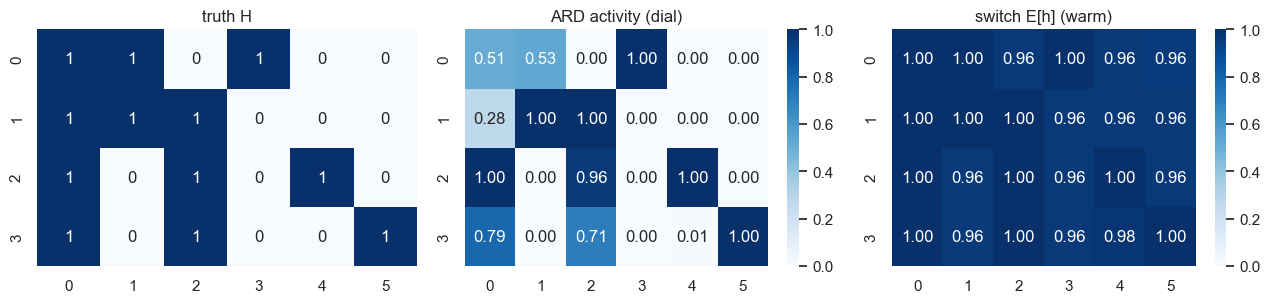

In [13]:
row = q4[(q4.arm == "switch_warm") & (q4.seed == 0)].iloc[0]
ds0, _ = ex.level_data(LEVEL, 0)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))
sns.heatmap(ds0.H, ax=axes[0], cmap="Blues", cbar=False, annot=True); axes[0].set_title("truth H")
ard_row = q4[(q4.arm == "ARD") & (q4.seed == 0)].iloc[0]
sns.heatmap(mt.activity(ard_row["ard"])[:, ard_row["match_idx"]], ax=axes[1], cmap="Blues",
            annot=True, fmt=".2f", vmin=0, vmax=1); axes[1].set_title("ARD activity (dial)")
sns.heatmap(row["E_h"][:, row["match_idx"]], ax=axes[2], cmap="Blues", annot=True, fmt=".2f",
            vmin=0, vmax=1); axes[2].set_title("switch E[h] (warm)")
plt.tight_layout(); plt.show()

In [14]:
outcome(ex.decide_q4(q4))

> **Observed outcome: O1** — CLEANER: best switch (switch_warm) matches ARD (AUC 0.98 vs 0.95) and 100% of its calls are decisive (<0.1 or >0.9).

'O1'

## Q5 — Do forced zeros pin the factors down better than learned zeros?

Mix a shared factor into a private one by rotating them. A *forced* zero (‘factor 2 never appears in
view 1’) should make that rotation impossible. A *learned* zero can simply be switched back on.
How much does the model resist the rotation in each case, and does the resistance grow with the
number of samples?

| Outcome | Name | What we would see | What it would mean |
|---|---|---|---|
| **O1** | Flat | $\Delta < 5$ nats at the larger $N$ | rotation is essentially free |
| **O2** | Grows like N | gap ratio $\ge 0.6\times$ the sample ratio | pinned at likelihood level (`lem:zeros` regime) |
| **O3** | Grows slower than N | otherwise | a real penalty, but not identification |

*Full mathematical statement: notebook 00.*

In [15]:
q5 = ex.run_q5(LEVEL, seeds=range(2))
q5.to_csv(os.path.join(RESULTS, f"{LEVEL}_q5.csv"), index=False)
print("all freeze fits monotone:", bool(q5.monotone.all()))
q5.groupby(["arm", "N", "theta"])["gap"].mean().unstack("theta")

all freeze fits monotone: True


theta                       0        10        20        30        45
arm                   N                                              
ARD (no switch)       150  0.0   43.123    73.656    87.562    90.952
                      600  0.0   80.139   114.577   130.221   138.883
frozen (true pattern) 150  0.0   91.154   313.063   609.161  1086.782
                      600  0.0  350.888  1225.260  2387.969  4226.409
learned switch        150  0.0   42.524    72.002    85.902    89.275
                      600  0.0   79.488   113.928   129.571   138.233

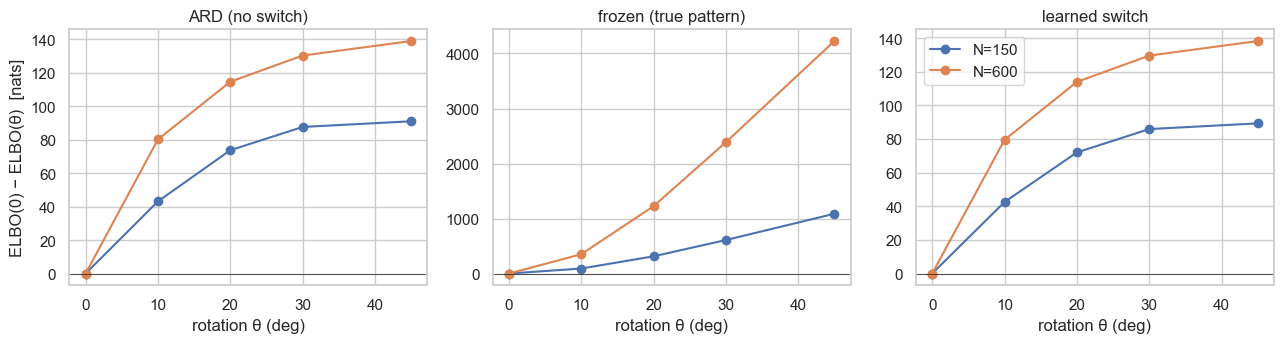

In [16]:
fig, axes = plt.subplots(1, len(q5.arm.unique()), figsize=(13, 3.6), sharey=False)
for ax, (arm, d) in zip(axes, q5.groupby("arm")):
    for N, dn in d.groupby("N"):
        g = dn.groupby("theta")["gap"].mean()
        ax.plot(g.index, g.values, "o-", label=f"N={N}")
    ax.set_title(arm); ax.set_xlabel("rotation θ (deg)"); ax.axhline(0, color="k", lw=.5)
axes[0].set_ylabel("ELBO(0) − ELBO(θ)  [nats]"); axes[-1].legend()
plt.tight_layout(); plt.show()

In [17]:
for arm, oc in ex.decide_q5(q5).items():
    outcome(oc, title=f"Observed outcome [{arm}]")

> **Observed outcome [ARD (no switch)]: O3** — GROWS SLOWER THAN N: gap 91 -> 139 (x1.5 for x4 samples): a penalty, but not likelihood-level identification.

> **Observed outcome [frozen (true pattern)]: O2** — GROWS LIKE N: gap 1087 -> 4226 nats (x3.9 for x4 samples). The split is pinned at likelihood level.

> **Observed outcome [learned switch]: O3** — GROWS SLOWER THAN N: gap 89 -> 138 (x1.5 for x4 samples): a penalty, but not likelihood-level identification.

## Q6 — One sharing rate for the whole model, or one per factor?

A single $\pi$ says ‘in this dataset, factors are mostly shared (or mostly private)’. A rate $\pi_k$
per factor says ‘factor $k$ is shared’. But $\pi_k$ is learned from only $M$ switches. Is it worth it?

| Outcome | Name | What we would see | What it would mean |
|---|---|---|---|
| **O1** | Either works | sd$(\pi_k)<0.15$ at $M\le4$, no AUC gain | choose by interpretability |
| **O2** | Use one global $\pi$ | sd$(\pi_k)\ge0.15$ at $M\le4$, no AUC gain | per-factor rates are noise at realistic $M$ |
| **O3** | Per-factor helps | AUC gain $\ge0.03$ at some $M$ | keep $\pi_k$ where it helps |

*Full mathematical statement: notebook 00.*

In [18]:
q6 = ex.run_q6(LEVEL, seeds=SEEDS)
q6.to_csv(os.path.join(RESULTS, f"{LEVEL}_q6.csv"), index=False)
q6.groupby(["M", "mode"])[["auc_h", "decisive_h", "pi_sd", "pi_sep", "min_corr"]].mean()

auc_h  decisive_h  pi_sd  pi_sep  min_corr
M mode                                                  
2 global      0.750         1.0  0.135     NaN     0.241
  per_factor  0.750         1.0  0.202   0.250     0.241
4 global      0.954         1.0  0.080     NaN     0.357
  per_factor  0.954         1.0  0.170   0.508     0.357
8 global      0.989         1.0  0.040     NaN     0.224
  per_factor  0.989         1.0  0.119   0.702     0.224

In [19]:
outcome(ex.decide_q6(q6))

> **Observed outcome: O2** — USE ONE GLOBAL PI: per-factor pi_k is uncertain at M <= 4 (posterior sd 0.19) and does not improve recovery (largest AUC gain +0.00).

'O2'

## Summary of this notebook

The outcome lines above are collected, with the other levels, in `notebooks_sharedness/REPORT.md`.